# 3D Parallelism Power Scaling Analysis

Tests three hypotheses about average steady-state cluster power as the
number of nodes scales from n=2 to n=8 on GPT-2 medium training:

**H1.** The TP-heavy configuration (max valid TP for that n) is the
       *lowest* avg steady-state power at every node count.

**H2.** Pure data parallelism (DP = world size) loses its power advantage
       as nodes scale — its relative rank should drift upward (worse) with n.

**H3.** Balanced PP-DP configurations (DP ≈ PP with TP = 1) become the
       *highest* avg steady-state power as nodes scale.

Reads sidecar `rank*.csv` traces from every successful config under
`power_logs/gpt2_medium_n{N}_<SWEEP_ID>/`.

In [35]:
import os
import re
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Color per config category (used consistently in every plot below).
CAT_COLORS = {
    "TP=W":   "#2e7d32",  # green   — max-TP (closest to TP = world size)
    "DP=W":   "#1565c0",  # blue    — pure DP (DP = world size)
    "PP=max": "#ef6c00",  # orange  — max-PP (PP-heavy)
    "DP=PP":  "#c62828",  # red     — balanced DP≈PP with TP=1
    "other":  "#cfd8dc",  # grey    — everything else
}

## Configuration

In [36]:
def _find_project_root():
    project_dir = os.environ.get("PROJECT_DIR")
    if project_dir:
        return Path(project_dir).expanduser().resolve()

    start = Path.cwd().resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "power_logs").exists() and (candidate / "notebooks").exists():
            return candidate

    raise RuntimeError(
        "Could not find the project root. Run this notebook from the repo "
        "or set PROJECT_DIR=/path/to/scheduling-carbon-aware-3d-parallelism."
    )


BASE = _find_project_root()
SWEEP_ID      = "20260512_114447"
MODEL         = "gpt2_medium"
NODE_COUNTS   = [2, 4, 6, 8]
GPUS_PER_NODE = 4

INTERVAL_SECONDS = 0.5    # sidecar sampling interval
WARMUP_FRAC      = 0.20   # drop first 20% of samples for steady-state

PLOTS_DIR = BASE / "figures" / "experiment_plots" / f"{MODEL}_sweep_{SWEEP_ID}"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Base:       {BASE}")
print(f"Sweep ID:   {SWEEP_ID}")
print(f"Model:      {MODEL}")
print(f"Plots out:  {PLOTS_DIR}")

Base:       /u/data3/wat29/scheduling-carbon-aware-3d-parallelism
Sweep ID:   20260512_114447
Model:      gpt2_medium
Plots out:  /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/gpt2_medium_sweep_20260512_114447


## Load every successful config

In [37]:
CFG_RE = re.compile(r"^tp(\d+)_pp(\d+)_dp(\d+)$")


def parse_cfg(name):
    m = CFG_RE.match(name)
    if not m:
        return None
    tp, pp, dp = map(int, m.groups())
    return {"tp": tp, "pp": pp, "dp": dp, "name": name}


def load_config(cfg_dir):
    """Return cluster power trace by summing every rank*.csv in the folder."""
    rank_files = sorted(glob.glob(str(cfg_dir / "rank*.csv")))
    if not rank_files:
        return None
    series = {}
    for f in rank_files:
        rank = int(re.search(r"rank(\d+)", os.path.basename(f)).group(1))
        df_r = pd.read_csv(f)
        if "total_power_W" not in df_r.columns or len(df_r) < 2:
            continue
        series[rank] = df_r["total_power_W"].to_numpy()
    if not series:
        return None
    n_min = min(len(v) for v in series.values())
    series = {r: v[:n_min] for r, v in series.items()}
    cluster = np.sum(np.stack(list(series.values())), axis=0)
    return {
        "rank_power": series,
        "cluster_power": cluster,
        "time": np.arange(n_min) * INTERVAL_SECONDS,
        "n_ranks": len(series),
    }


records = []
for n in NODE_COUNTS:
    sweep_dir = BASE / "power_logs" / f"{MODEL}_n{n}_{SWEEP_ID}"
    if not sweep_dir.exists():
        print(f"[warn] missing parent folder: {sweep_dir}")
        continue

    print(f"\n--- n={n}: {sweep_dir.name} ---")
    for d in sorted(os.listdir(sweep_dir)):
        cfg_dir = sweep_dir / d
        if not cfg_dir.is_dir():
            continue
        cfg = parse_cfg(d)
        if cfg is None:
            continue

        status_file = cfg_dir / "status.txt"
        status = status_file.read_text().strip() if status_file.exists() else "missing"
        if not status.startswith("OK"):
            print(f"  [skip] {d}: status={status}")
            continue

        data = load_config(cfg_dir)
        if data is None:
            print(f"  [skip] {d}: no usable rank CSVs")
            continue

        p = data["cluster_power"]
        warmup = int(len(p) * WARMUP_FRAC)
        steady = p[warmup:] if len(p) > warmup else p

        records.append({
            "n_nodes":            n,
            "world_size":         n * GPUS_PER_NODE,
            "tp":                 cfg["tp"],
            "pp":                 cfg["pp"],
            "dp":                 cfg["dp"],
            "config":             d,
            "n_ranks":            data["n_ranks"],
            "duration_s":         len(p) * INTERVAL_SECONDS,
            "steady_avg_power_w": float(steady.mean()),
            "peak_power_w":       float(p.max()),
            "energy_wh":          float(p.sum()) * INTERVAL_SECONDS / 3600,
            "_cluster_power":     p,
            "_time":              data["time"],
        })

df = pd.DataFrame(records)
print(f"\nLoaded {len(df)} OK configs across {df['n_nodes'].nunique()} node counts:")
print(df.groupby("n_nodes").size().to_string())


--- n=2: gpt2_medium_n2_20260512_114447 ---

--- n=4: gpt2_medium_n4_20260512_114447 ---

--- n=6: gpt2_medium_n6_20260512_114447 ---
  [skip] tp1_pp8_dp3: status=FAILED rc=1
  [skip] tp2_pp4_dp3: status=FAILED rc=143

--- n=8: gpt2_medium_n8_20260512_114447 ---
  [skip] tp2_pp8_dp2: status=FAILED rc=1
  [skip] tp8_pp4_dp1: status=FAILED rc=1

Loaded 57 OK configs across 4 node counts:
n_nodes
2    10
4    14
6    18
8    15


## Tag each config with a hypothesis category

For each node count:
- **TP=W**: highest TP value present in the valid configs at that n.
  At n=2 and n=4 this literally equals the world size (TP=W). At n=6 and
  n=8 the constraint `HEADS=16 mod TP == 0` caps TP, so we use max-valid-TP.
- **DP=W**: DP equals world size (pure data parallelism).
- **PP=max**: highest PP value present.
- **DP=PP**: TP=1, both PP>1 and DP>1, and |PP - DP| is minimised among
  such configs.

In [38]:
max_tp_per_n = df.groupby("n_nodes")["tp"].max().to_dict()
max_pp_per_n = df.groupby("n_nodes")["pp"].max().to_dict()

print("Max valid TP per node count:", max_tp_per_n)
print("Max valid PP per node count:", max_pp_per_n)


def pick_dp_pp(group):
    cand = group[(group["tp"] == 1) & (group["pp"] > 1) & (group["dp"] > 1)].copy()
    if cand.empty:
        return None
    cand["abs_diff"] = (cand["pp"] - cand["dp"]).abs()
    return cand.sort_values(["abs_diff", "pp"], ascending=[True, False]).iloc[0]["config"]


dp_pp_picks = {n: pick_dp_pp(g) for n, g in df.groupby("n_nodes")}
print("\nDP=PP balanced pick per node count:")
for n, c in dp_pp_picks.items():
    print(f"  n={n}: {c}")


def categorise(row):
    n = row["n_nodes"]
    if row["config"] == dp_pp_picks.get(n):
        return "DP=PP"
    if row["tp"] == max_tp_per_n[n]:
        return "TP=W"
    if row["dp"] == row["world_size"]:
        return "DP=W"
    if row["pp"] == max_pp_per_n[n]:
        return "PP=max"
    return "other"


df["category"] = df.apply(categorise, axis=1)
df["rank"] = df.groupby("n_nodes")["steady_avg_power_w"].rank(method="min").astype(int)
df["n_cfgs_at_n"] = df.groupby("n_nodes")["n_nodes"].transform("count")
df["rank_pct"] = (df["rank"] - 1) / (df["n_cfgs_at_n"] - 1)

print("\nCategory counts:")
print(df["category"].value_counts().to_string())

Max valid TP per node count: {2: 8, 4: 16, 6: 8, 8: 16}
Max valid PP per node count: {2: 8, 4: 8, 6: 24, 8: 8}

DP=PP balanced pick per node count:
  n=2: tp1_pp4_dp2
  n=4: tp1_pp4_dp4
  n=6: tp1_pp6_dp4
  n=8: tp1_pp8_dp4

Category counts:
category
other     38
TP=W       6
PP=max     5
DP=W       4
DP=PP      4


## Plot 1 — Ranked power per node count

For each n, every config sorted ascending by avg steady-state power.
Key categories are labelled above their bars. **Direct test of H1**:
if TP=W is the leftmost bar in all four panels, H1 holds.

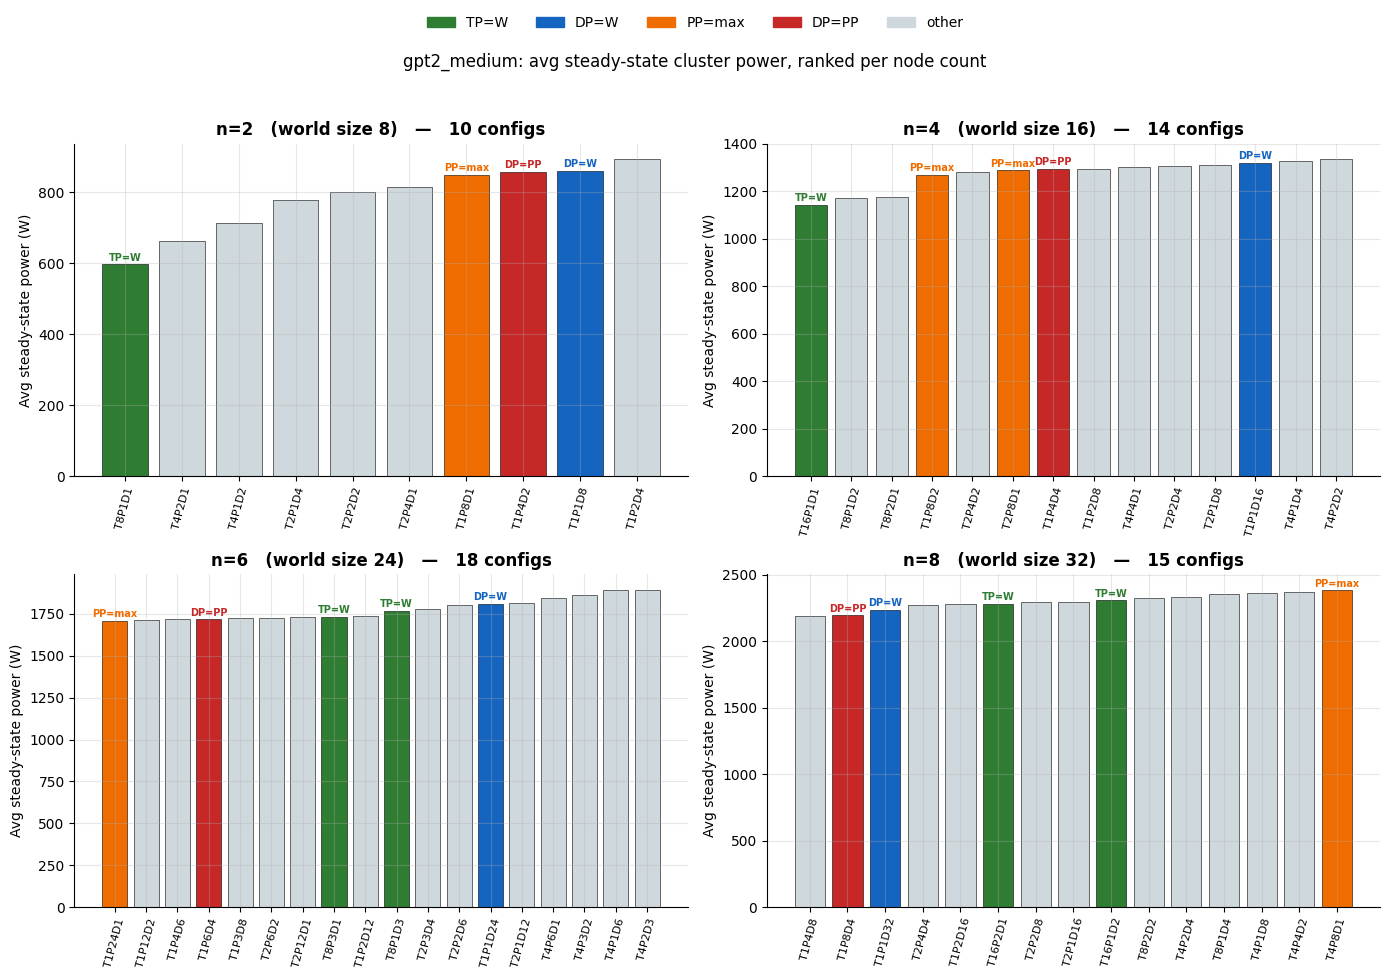

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=False)
axes = axes.flatten()

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n].sort_values("steady_avg_power_w").reset_index(drop=True)
    if sub.empty:
        ax.set_title(f"n={n}: no data")
        continue

    colors = [CAT_COLORS[c] for c in sub["category"]]
    labels = [f"T{r.tp}P{r.pp}D{r.dp}" for r in sub.itertuples()]

    ax.bar(range(len(sub)), sub["steady_avg_power_w"], color=colors,
           edgecolor="black", linewidth=0.4)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(labels, rotation=75, fontsize=8)
    ax.set_ylabel("Avg steady-state power (W)")
    ax.set_title(f"n={n}   (world size {n * GPUS_PER_NODE})   —   {len(sub)} configs",
                 fontweight="bold")

    for i, (_, r) in enumerate(sub.iterrows()):
        if r["category"] in {"TP=W", "DP=W", "PP=max", "DP=PP"}:
            ax.text(i, r["steady_avg_power_w"] * 1.005,
                    r["category"], ha="center", va="bottom", fontsize=7,
                    color=CAT_COLORS[r["category"]], fontweight="bold")

handles = [mpatches.Patch(color=v, label=k) for k, v in CAT_COLORS.items()]
fig.legend(handles=handles, loc="upper center", ncol=5,
           bbox_to_anchor=(0.5, 0.98), frameon=False)
fig.suptitle(f"{MODEL}: avg steady-state cluster power, ranked per node count", y=0.93)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.savefig(PLOTS_DIR / "01_ranked_power_per_n.png", dpi=120, bbox_inches="tight")
plt.show()

## Plot 2 — Scaling of key strategies (absolute power)

X = node count, Y = avg steady-state cluster power, one coloured line per
category. Grey band shows min-to-max spread of all configs at each n.

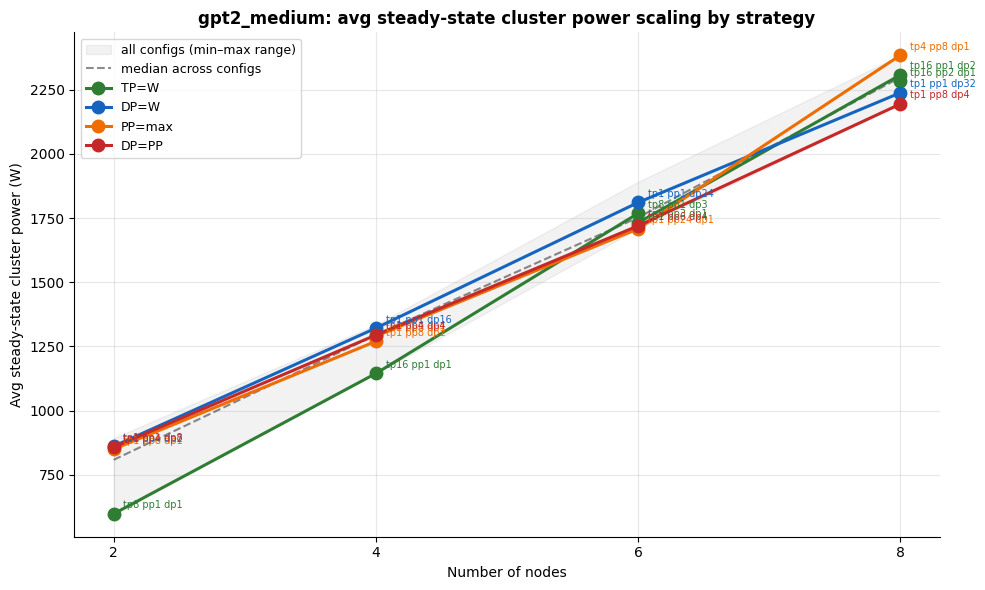

In [40]:
fig, ax = plt.subplots(figsize=(10, 6))

agg = df.groupby("n_nodes")["steady_avg_power_w"].agg(["min", "max", "median"])
ax.fill_between(agg.index, agg["min"], agg["max"], color="gray", alpha=0.10,
                label="all configs (min–max range)")
ax.plot(agg.index, agg["median"], color="black", linestyle="--", alpha=0.45,
        label="median across configs")

for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
    sub = df[df["category"] == cat].sort_values("n_nodes")
    if sub.empty:
        continue
    ax.plot(sub["n_nodes"], sub["steady_avg_power_w"], "o-",
            color=CAT_COLORS[cat], label=cat, linewidth=2.2, markersize=9)
    for _, r in sub.iterrows():
        ax.annotate(r["config"].replace("_", " "),
                    xy=(r["n_nodes"], r["steady_avg_power_w"]),
                    xytext=(7, 4), textcoords="offset points", fontsize=7,
                    color=CAT_COLORS[cat])

ax.set_xlabel("Number of nodes")
ax.set_ylabel("Avg steady-state cluster power (W)")
ax.set_xticks(NODE_COUNTS)
ax.set_title(f"{MODEL}: avg steady-state cluster power scaling by strategy",
             fontweight="bold")
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "02_scaling_absolute.png", dpi=120, bbox_inches="tight")
plt.show()

## Plot 3 — Scaling of relative rank (0 = lowest power, 1 = highest)

**Direct test of all three hypotheses.** Within each n, configs are ranked
ascending by avg steady-state power and mapped onto [0, 1].
- H1: TP=W line should sit at 0.
- H2: DP=W line should rise with n.
- H3: DP=PP line should rise toward 1.

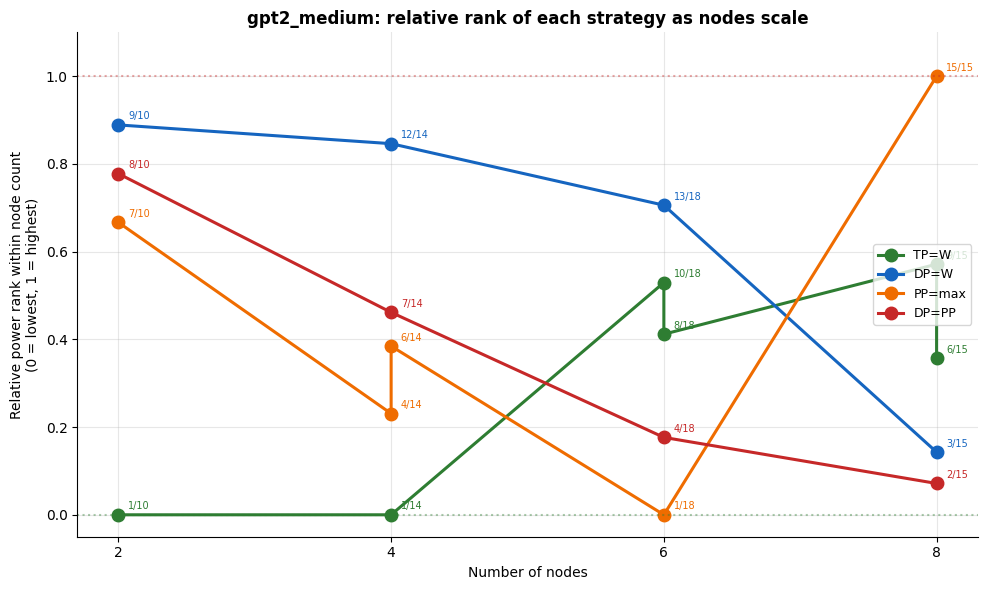

In [41]:
fig, ax = plt.subplots(figsize=(10, 6))

for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
    sub = df[df["category"] == cat].sort_values("n_nodes")
    if sub.empty:
        continue
    ax.plot(sub["n_nodes"], sub["rank_pct"], "o-",
            color=CAT_COLORS[cat], label=cat, linewidth=2.2, markersize=9)
    for _, r in sub.iterrows():
        ax.annotate(f"{int(r['rank'])}/{int(r['n_cfgs_at_n'])}",
                    xy=(r["n_nodes"], r["rank_pct"]),
                    xytext=(7, 4), textcoords="offset points", fontsize=7,
                    color=CAT_COLORS[cat])

ax.axhline(0.0, color=CAT_COLORS["TP=W"], linestyle=":", alpha=0.4)
ax.axhline(1.0, color=CAT_COLORS["DP=PP"], linestyle=":", alpha=0.4)
ax.set_xlabel("Number of nodes")
ax.set_ylabel("Relative power rank within node count\n(0 = lowest, 1 = highest)")
ax.set_xticks(NODE_COUNTS)
ax.set_ylim(-0.05, 1.10)
ax.set_title(f"{MODEL}: relative rank of each strategy as nodes scale",
             fontweight="bold")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "03_scaling_rank.png", dpi=120, bbox_inches="tight")
plt.show()

## Plot 4 — Sample cluster power traces (key configs, post-warmup)

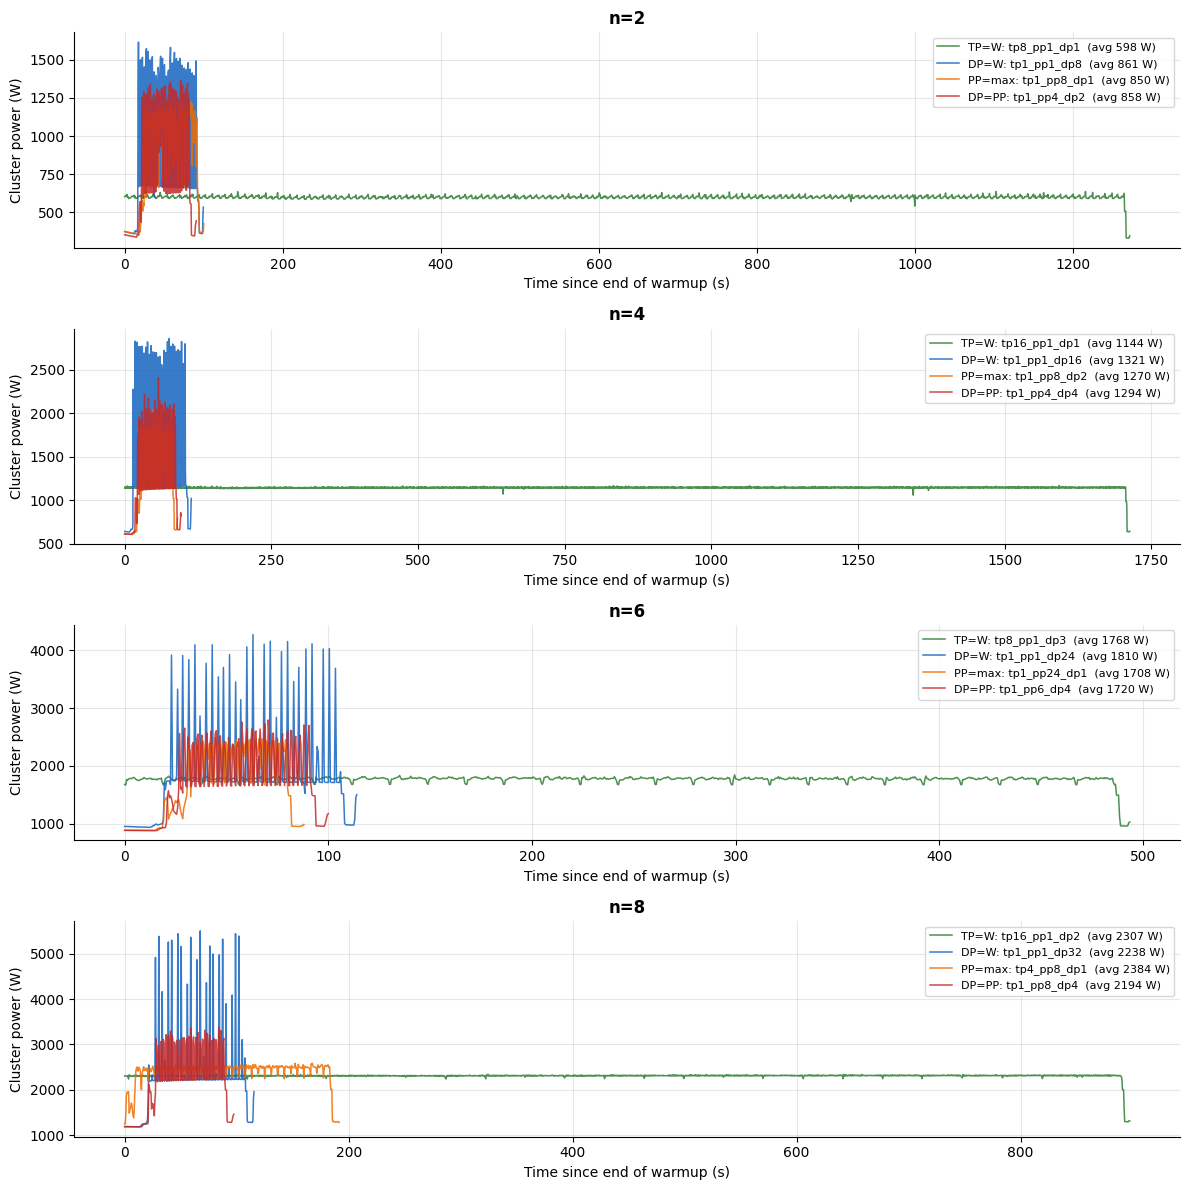

In [42]:
fig, axes = plt.subplots(len(NODE_COUNTS), 1, figsize=(12, 3 * len(NODE_COUNTS)))
if len(NODE_COUNTS) == 1:
    axes = [axes]

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n]
    plotted_any = False
    for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
        s = sub[sub["category"] == cat]
        if s.empty:
            continue
        row = s.iloc[0]
        p = row["_cluster_power"]
        t = row["_time"]
        warmup = int(len(p) * WARMUP_FRAC)
        t_steady, p_steady = t[warmup:] - t[warmup], p[warmup:]
        ax.plot(t_steady, p_steady, color=CAT_COLORS[cat],
                label=f"{cat}: {row['config']}  (avg {row['steady_avg_power_w']:.0f} W)",
                linewidth=1.1, alpha=0.85)
        plotted_any = True

    ax.set_title(f"n={n}", fontweight="bold")
    ax.set_xlabel("Time since end of warmup (s)")
    ax.set_ylabel("Cluster power (W)")
    if plotted_any:
        ax.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "04_traces_key_configs.png", dpi=120, bbox_inches="tight")
plt.show()

## Summary tables

In [43]:
key_rows = []
for n in NODE_COUNTS:
    sub = df[df["n_nodes"] == n]
    if sub.empty:
        continue
    actual_min = sub.sort_values("steady_avg_power_w").iloc[0]
    actual_max = sub.sort_values("steady_avg_power_w").iloc[-1]
    for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
        s = sub[sub["category"] == cat]
        if s.empty:
            continue
        r = s.iloc[0]
        key_rows.append({
            "n_nodes":         n,
            "world_size":      n * GPUS_PER_NODE,
            "category":        cat,
            "config":          r["config"],
            "avg_steady_W":    round(r["steady_avg_power_w"], 1),
            "rank":            int(r["rank"]),
            "of_n_configs":    int(r["n_cfgs_at_n"]),
            "rank_pct":        round(r["rank_pct"], 2),
            "is_global_min":   r["config"] == actual_min["config"],
            "is_global_max":   r["config"] == actual_max["config"],
        })

key_summary = pd.DataFrame(key_rows)
print("\nKey-configuration summary:")
print(key_summary.to_string(index=False))
key_summary.to_csv(PLOTS_DIR / "summary_key_configs.csv", index=False)

full = df.drop(columns=["_cluster_power", "_time"]).copy()
full.to_csv(PLOTS_DIR / "summary_all_configs.csv", index=False)
print(f"\nSaved tables and plots under {PLOTS_DIR}")


Key-configuration summary:
 n_nodes  world_size category       config  avg_steady_W  rank  of_n_configs  rank_pct  is_global_min  is_global_max
       2           8     TP=W  tp8_pp1_dp1         597.6     1            10      0.00           True          False
       2           8     DP=W  tp1_pp1_dp8         860.8     9            10      0.89          False          False
       2           8   PP=max  tp1_pp8_dp1         849.7     7            10      0.67          False          False
       2           8    DP=PP  tp1_pp4_dp2         857.5     8            10      0.78          False          False
       4          16     TP=W tp16_pp1_dp1        1144.5     1            14      0.00           True          False
       4          16     DP=W tp1_pp1_dp16        1321.1    12            14      0.85          False          False
       4          16   PP=max  tp1_pp8_dp2        1269.6     4            14      0.23          False          False
       4          16    DP=PP  tp1_p

## Hypothesis evaluation (programmatic)

In [44]:
print("=" * 78)
print("H1: TP=W (max-TP) is the lowest avg steady-state power at each n")
print("=" * 78)
for n in NODE_COUNTS:
    sub = df[df["n_nodes"] == n].sort_values("steady_avg_power_w")
    if sub.empty:
        continue
    tp_w = sub[sub["category"] == "TP=W"]
    if tp_w.empty:
        print(f"  n={n}: no TP=W config detected (skipped)")
        continue
    actual_min = sub.iloc[0]
    r = tp_w.iloc[0]
    verdict = "HOLDS" if r["config"] == actual_min["config"] else "FAILS"
    print(f"  n={n}:   actual min = {actual_min['config']:>16s} "
          f"({actual_min['steady_avg_power_w']:6.0f} W)   "
          f"TP=W = {r['config']:>16s} "
          f"({r['steady_avg_power_w']:6.0f} W, rank {int(r['rank'])}/{int(r['n_cfgs_at_n'])})"
          f"   → {verdict}")

print()
print("=" * 78)
print("H2: DP=W (pure DP) loses its power advantage as n grows")
print("    (rank_pct should rise toward 1 with n)")
print("=" * 78)
dp_w = df[df["category"] == "DP=W"].sort_values("n_nodes")
prev_pct = None
for _, r in dp_w.iterrows():
    delta = "" if prev_pct is None else f"  Δ={r['rank_pct'] - prev_pct:+.2f}"
    print(f"  n={int(r['n_nodes'])}: {r['config']:>16s} "
          f"({r['steady_avg_power_w']:6.0f} W)   "
          f"rank {int(r['rank']):2d}/{int(r['n_cfgs_at_n'])}   "
          f"rank_pct={r['rank_pct']:.2f}{delta}")
    prev_pct = r["rank_pct"]

print()
print("=" * 78)
print("H3: DP=PP (balanced DP≈PP, TP=1) becomes the highest power as n grows")
print("    (rank_pct should rise toward 1 with n)")
print("=" * 78)
dp_pp = df[df["category"] == "DP=PP"].sort_values("n_nodes")
prev_pct = None
for _, r in dp_pp.iterrows():
    delta = "" if prev_pct is None else f"  Δ={r['rank_pct'] - prev_pct:+.2f}"
    print(f"  n={int(r['n_nodes'])}: {r['config']:>16s} "
          f"({r['steady_avg_power_w']:6.0f} W)   "
          f"rank {int(r['rank']):2d}/{int(r['n_cfgs_at_n'])}   "
          f"rank_pct={r['rank_pct']:.2f}{delta}")
    prev_pct = r["rank_pct"]

print()
print("=" * 78)
print("Cross-strategy ordering at each n  (lowest → highest avg steady power)")
print("=" * 78)
for n in NODE_COUNTS:
    sub = df[df["n_nodes"] == n].sort_values("steady_avg_power_w")
    if sub.empty:
        continue
    keys = sub[sub["category"].isin(["TP=W", "DP=W", "PP=max", "DP=PP"])]
    chain = "  <  ".join(
        f"{r['category']}({r['steady_avg_power_w']:.0f}W)" for _, r in keys.iterrows()
    )
    print(f"  n={n}: {chain}")

H1: TP=W (max-TP) is the lowest avg steady-state power at each n
  n=2:   actual min =      tp8_pp1_dp1 (   598 W)   TP=W =      tp8_pp1_dp1 (   598 W, rank 1/10)   → HOLDS
  n=4:   actual min =     tp16_pp1_dp1 (  1144 W)   TP=W =     tp16_pp1_dp1 (  1144 W, rank 1/14)   → HOLDS
  n=6:   actual min =     tp1_pp24_dp1 (  1708 W)   TP=W =      tp8_pp3_dp1 (  1732 W, rank 8/18)   → FAILS
  n=8:   actual min =      tp1_pp4_dp8 (  2193 W)   TP=W =     tp16_pp2_dp1 (  2283 W, rank 6/15)   → FAILS

H2: DP=W (pure DP) loses its power advantage as n grows
    (rank_pct should rise toward 1 with n)
  n=2:      tp1_pp1_dp8 (   861 W)   rank  9/10   rank_pct=0.89
  n=4:     tp1_pp1_dp16 (  1321 W)   rank 12/14   rank_pct=0.85  Δ=-0.04
  n=6:     tp1_pp1_dp24 (  1810 W)   rank 13/18   rank_pct=0.71  Δ=-0.14
  n=8:     tp1_pp1_dp32 (  2238 W)   rank  3/15   rank_pct=0.14  Δ=-0.56

H3: DP=PP (balanced DP≈PP, TP=1) becomes the highest power as n grows
    (rank_pct should rise toward 1 with n)
  n=2:

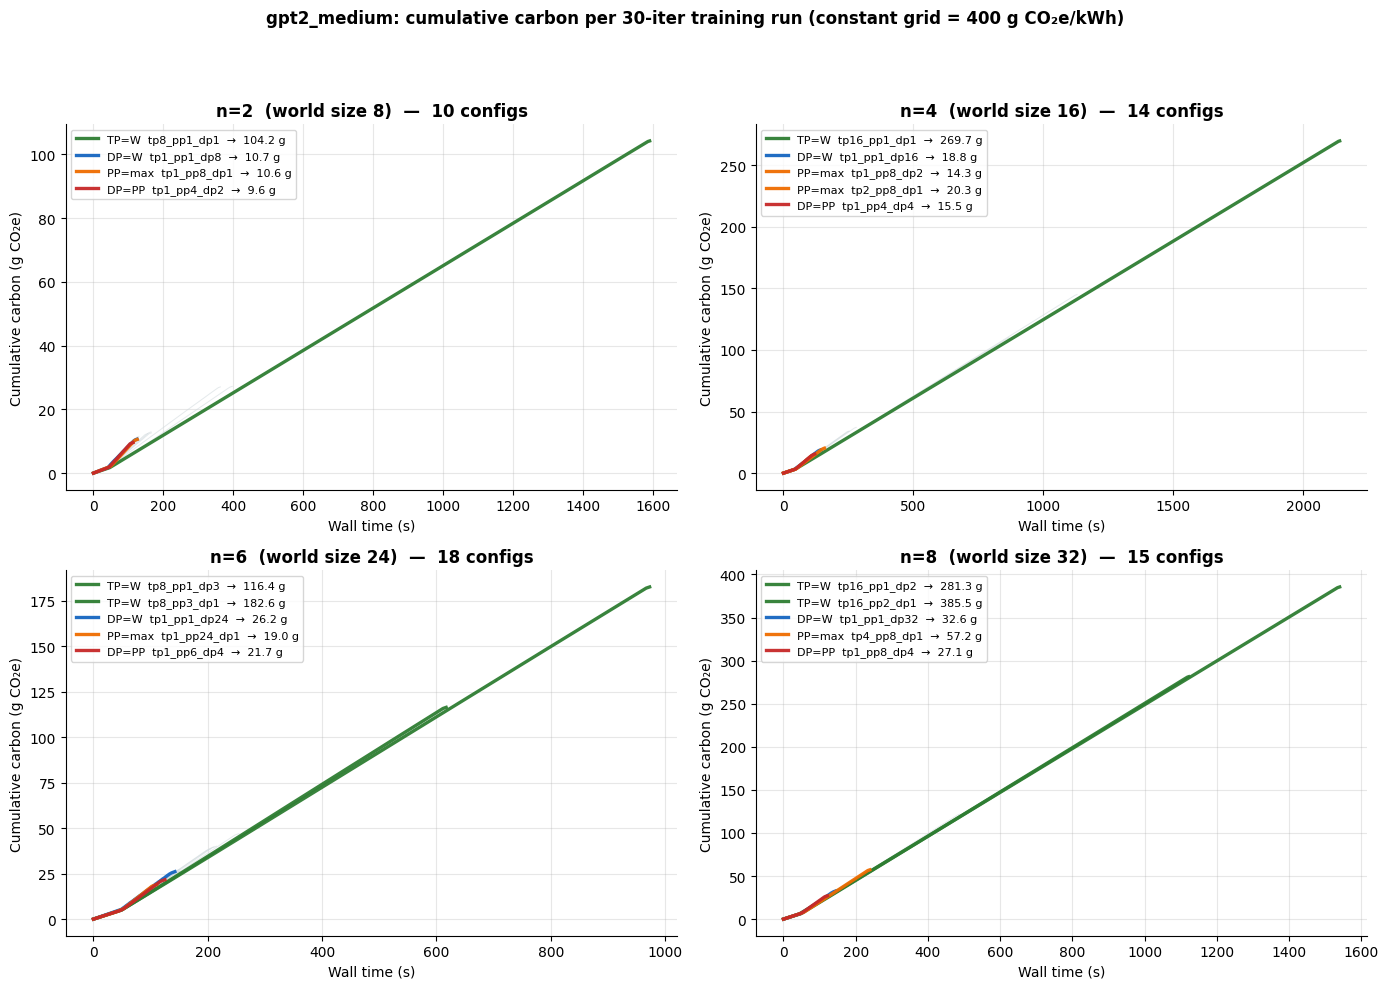


Total carbon per 30-iter run — key configurations:
 n_nodes category       config  duration_s  avg_power_W  total_gCO2e
       2    DP=PP  tp1_pp4_dp2       113.5        857.5         9.59
       2   PP=max  tp1_pp8_dp1       125.5        849.7        10.58
       2     DP=W  tp1_pp1_dp8       125.0        860.8        10.66
       2     TP=W  tp8_pp1_dp1      1589.5        597.6       104.22
       4   PP=max  tp1_pp8_dp2       113.0       1269.6        14.30
       4    DP=PP  tp1_pp4_dp4       120.5       1294.2        15.52
       4     DP=W tp1_pp1_dp16       142.5       1321.1        18.81
       4   PP=max  tp2_pp8_dp1       158.0       1289.6        20.27
       4     TP=W tp16_pp1_dp1      2141.5       1144.5       269.74
       6   PP=max tp1_pp24_dp1       110.5       1708.2        18.98
       6    DP=PP  tp1_pp6_dp4       125.5       1719.6        21.69
       6     DP=W tp1_pp1_dp24       143.0       1810.5        26.15
       6     TP=W  tp8_pp1_dp3       617.5       17

In [45]:
# %% [markdown]
# ## Plot 5 — Cumulative carbon over the run
#
# X = wall time (s). Y = running gCO₂e, computed from the cluster power
# trace times a constant grid intensity (400 gCO₂e / kWh).
#
# Final value of each line = total carbon for that config's 30-iter run.
# Lines that end earlier ran faster; lines that climb steeply drew more power.
# Greys in the background are the "other" configs (faded for context).

# %%
CARBON_INTENSITY_G_PER_KWH = 400.0
# 1 W × 1 s = 1 J = 1/3_600_000 kWh
CARBON_FACTOR = CARBON_INTENSITY_G_PER_KWH / 3_600_000   # multiply W·s → gCO₂e

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n]
    if sub.empty:
        ax.set_title(f"n={n}: no data")
        continue

    # Background: every "other" config in faded grey for context
    for _, r in sub[sub["category"] == "other"].iterrows():
        cum = np.cumsum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR
        ax.plot(r["_time"], cum, color=CAT_COLORS["other"],
                linewidth=0.7, alpha=0.55)

    # Foreground: the four key categories in full colour
    for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
        s = sub[sub["category"] == cat]
        for _, r in s.iterrows():
            cum = np.cumsum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR
            ax.plot(r["_time"], cum, color=CAT_COLORS[cat],
                    linewidth=2.4, alpha=0.95,
                    label=f"{cat}  {r['config']}  →  {cum[-1]:.1f} g")

    ax.set_xlabel("Wall time (s)")
    ax.set_ylabel("Cumulative carbon (g CO₂e)")
    ax.set_title(f"n={n}  (world size {n * GPUS_PER_NODE})  —  {len(sub)} configs",
                 fontweight="bold")
    ax.legend(fontsize=8, loc="upper left")

fig.suptitle(f"{MODEL}: cumulative carbon per 30-iter training run "
             f"(constant grid = {CARBON_INTENSITY_G_PER_KWH:.0f} g CO₂e/kWh)",
             y=0.985, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(PLOTS_DIR / "05_cumulative_carbon.png", dpi=120, bbox_inches="tight")
plt.show()

# Quick total-carbon summary table (key configs only)
rows = []
for _, r in df[df["category"].isin(["TP=W", "DP=W", "PP=max", "DP=PP"])].iterrows():
    total_g = float(np.sum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR)
    rows.append({
        "n_nodes":     r["n_nodes"],
        "category":    r["category"],
        "config":      r["config"],
        "duration_s":  round(r["duration_s"], 1),
        "avg_power_W": round(r["steady_avg_power_w"], 1),
        "total_gCO2e": round(total_g, 2),
    })
carbon_summary = pd.DataFrame(rows).sort_values(["n_nodes", "total_gCO2e"])
print("\nTotal carbon per 30-iter run — key configurations:")
print(carbon_summary.to_string(index=False))
carbon_summary.to_csv(PLOTS_DIR / "summary_carbon_key_configs.csv", index=False)

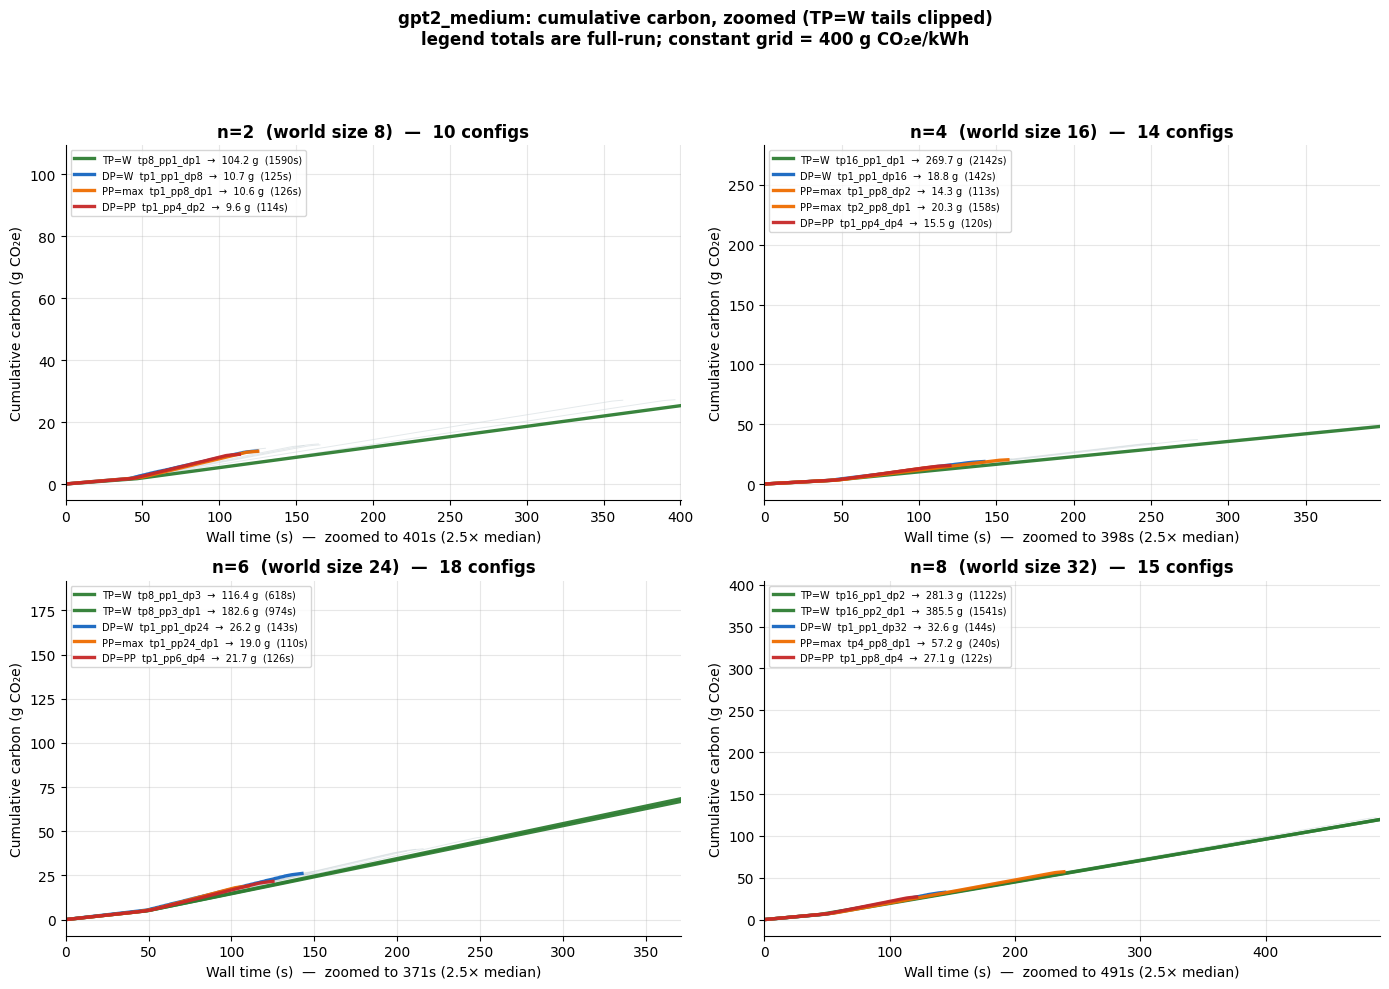

In [46]:
# %% [markdown]
# ## Plot 5b — Cumulative carbon, zoomed
# X-axis clipped to 2.5× the median duration at each n, so the long
# TP=W tails are cropped and we can see the other configs.
# Legend totals are still full-run.

# %%
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n]
    if sub.empty:
        ax.set_title(f"n={n}: no data")
        continue

    x_max = sub["duration_s"].median() * 2.5

    for _, r in sub[sub["category"] == "other"].iterrows():
        cum = np.cumsum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR
        ax.plot(r["_time"], cum, color=CAT_COLORS["other"], linewidth=0.7, alpha=0.55)

    for cat in ["TP=W", "DP=W", "PP=max", "DP=PP"]:
        s = sub[sub["category"] == cat]
        for _, r in s.iterrows():
            cum = np.cumsum(r["_cluster_power"]) * INTERVAL_SECONDS * CARBON_FACTOR
            ax.plot(r["_time"], cum, color=CAT_COLORS[cat], linewidth=2.4, alpha=0.95,
                    label=f"{cat}  {r['config']}  →  {cum[-1]:.1f} g  "
                          f"({r['duration_s']:.0f}s)")

    ax.set_xlim(0, x_max)
    ax.set_xlabel(f"Wall time (s)  —  zoomed to {x_max:.0f}s (2.5× median)")
    ax.set_ylabel("Cumulative carbon (g CO₂e)")
    ax.set_title(f"n={n}  (world size {n * GPUS_PER_NODE})  —  {len(sub)} configs",
                 fontweight="bold")
    ax.legend(fontsize=7, loc="upper left")

fig.suptitle(f"{MODEL}: cumulative carbon, zoomed (TP=W tails clipped)\n"
             f"legend totals are full-run; constant grid = "
             f"{CARBON_INTENSITY_G_PER_KWH:.0f} g CO₂e/kWh",
             y=0.985, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(PLOTS_DIR / "05b_cumulative_carbon_zoomed.png", dpi=120, bbox_inches="tight")
plt.show()

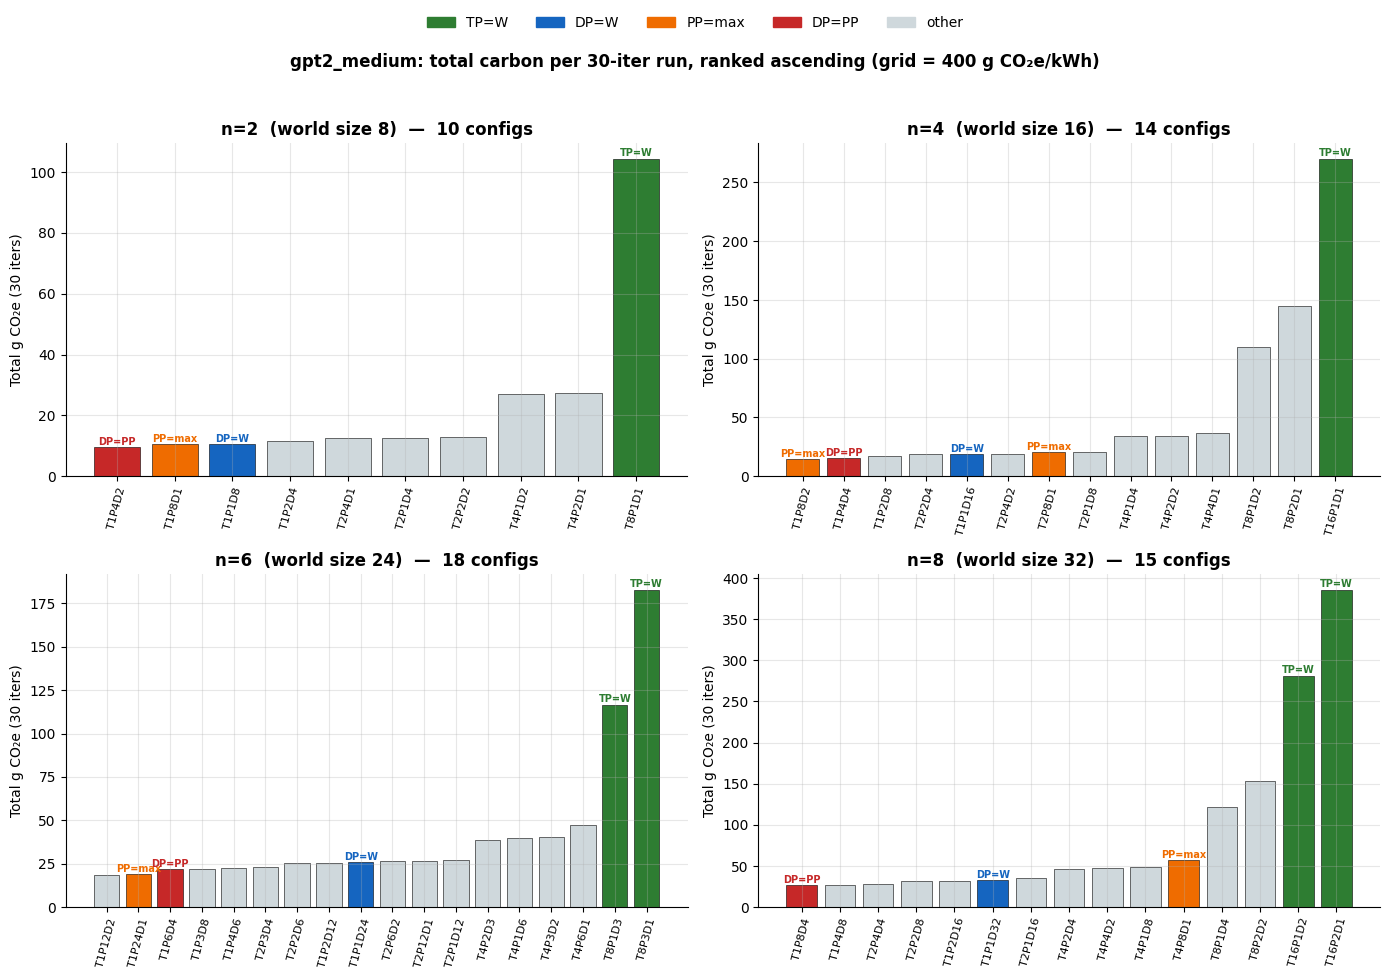

In [47]:
# %% [markdown]
# ## Plot 6 — Total carbon per 30-iter run, ranked ascending
# Final endpoint of each line in Plot 5, sorted. The picture that
# Plot 1 (ranked steady-state power) should be compared against.

# %%
df["total_gco2e"] = df["_cluster_power"].apply(
    lambda p: float(np.sum(p) * INTERVAL_SECONDS * CARBON_FACTOR)
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=False)
axes = axes.flatten()

for ax, n in zip(axes, NODE_COUNTS):
    sub = df[df["n_nodes"] == n].sort_values("total_gco2e").reset_index(drop=True)
    if sub.empty:
        ax.set_title(f"n={n}: no data")
        continue

    colors = [CAT_COLORS[c] for c in sub["category"]]
    labels = [f"T{r.tp}P{r.pp}D{r.dp}" for r in sub.itertuples()]

    ax.bar(range(len(sub)), sub["total_gco2e"], color=colors,
           edgecolor="black", linewidth=0.4)
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(labels, rotation=75, fontsize=8)
    ax.set_ylabel("Total g CO₂e (30 iters)")
    ax.set_title(f"n={n}  (world size {n * GPUS_PER_NODE})  —  {len(sub)} configs",
                 fontweight="bold")

    for i, (_, r) in enumerate(sub.iterrows()):
        if r["category"] in {"TP=W", "DP=W", "PP=max", "DP=PP"}:
            ax.text(i, r["total_gco2e"] * 1.005, r["category"],
                    ha="center", va="bottom", fontsize=7,
                    color=CAT_COLORS[r["category"]], fontweight="bold")

handles = [mpatches.Patch(color=v, label=k) for k, v in CAT_COLORS.items()]
fig.legend(handles=handles, loc="upper center", ncol=5,
           bbox_to_anchor=(0.5, 0.98), frameon=False)
fig.suptitle(f"{MODEL}: total carbon per 30-iter run, ranked ascending "
             f"(grid = {CARBON_INTENSITY_G_PER_KWH:.0f} g CO₂e/kWh)",
             y=0.93, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.savefig(PLOTS_DIR / "06_total_carbon_ranked.png", dpi=120, bbox_inches="tight")
plt.show()

Loaded 57 OK multinode configs; plotting 19 key configs.
 n_nodes key_category       config  steady_avg_power_w  throughput_tok_s  duration_s
       2       TP=max  tp8_pp1_dp1          597.644894       3710.751809      1589.5
       2       PP=max  tp1_pp8_dp1          849.699801      46997.928287       125.5
       2        DP=PP  tp1_pp4_dp2          857.501374      51966.872247       113.5
       2       DP=max  tp1_pp1_dp8          860.808750      47185.920000       125.0
       4       TP=max tp16_pp1_dp1         1144.498267       2754.256362      2141.5
       4       PP=max  tp1_pp8_dp2         1269.610276      52196.814159       113.0
       4       PP=max  tp2_pp8_dp1         1289.602055      37330.632911       158.0
       4        DP=PP  tp1_pp4_dp4         1294.224508      48948.049793       120.5
       4       DP=max tp1_pp1_dp16         1321.062149      41391.157895       142.5
       6       TP=max  tp8_pp1_dp3         1768.142662       9551.805668       617.5
       6

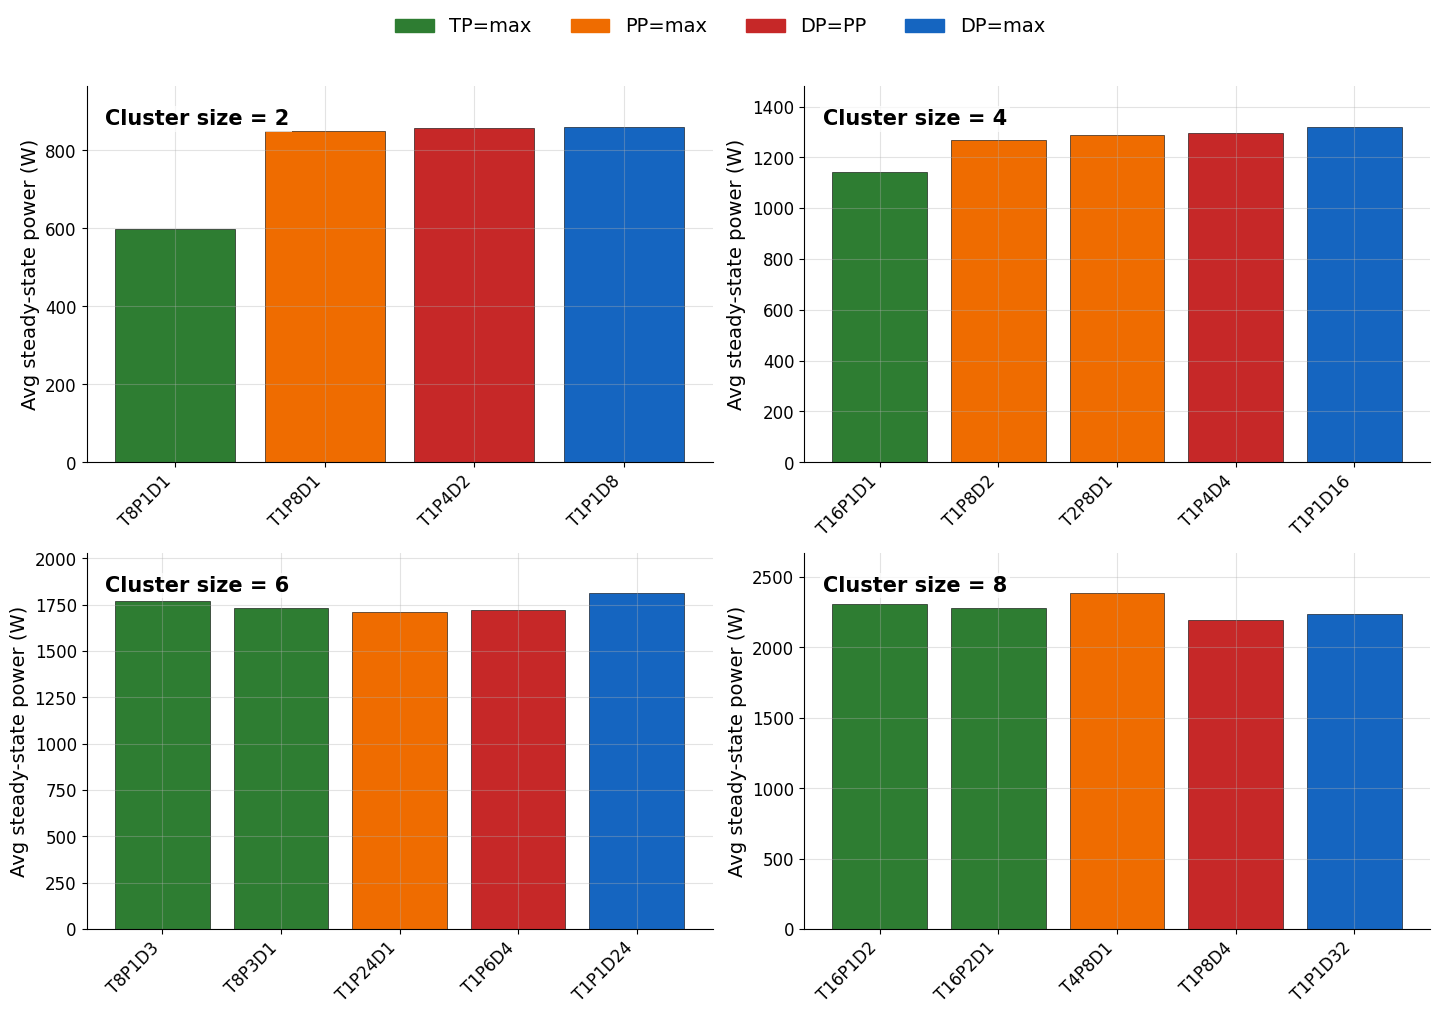

Saved: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/gpt2_medium_sweep_20260512_114447/key_config_power_panels.png


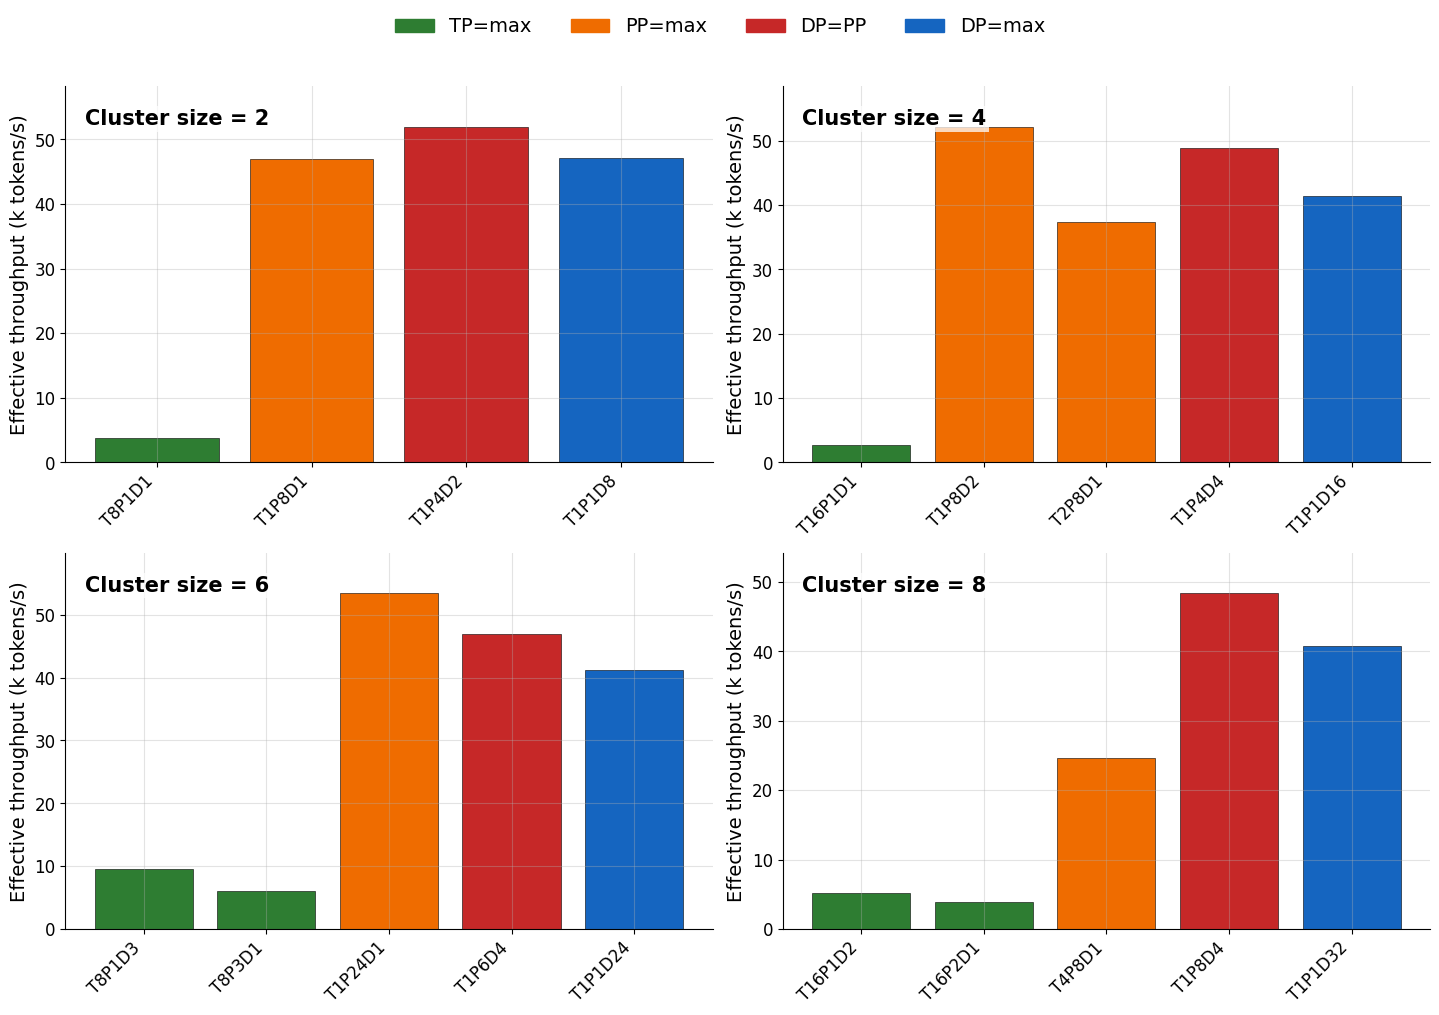

Saved: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/gpt2_medium_sweep_20260512_114447/key_config_throughput_panels.png
Saved: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/gpt2_medium_sweep_20260512_114447/key_power_throughput_panels.csv


In [48]:
# =====================================================================
# Multinode key-configuration power and throughput panels
# =====================================================================
from pathlib import Path
import glob
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


def find_repo_root_for_multinode(start=None):
    path = Path(start or os.getcwd()).resolve()
    for candidate in (path, *path.parents):
        if (candidate / "power_logs").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    if "BASE" in globals():
        return Path(BASE).resolve()
    raise RuntimeError(f"Could not find repo root from {path}")


MULTINODE_BASE = find_repo_root_for_multinode()
MULTINODE_MODEL = "gpt2_medium"
MULTINODE_SWEEP_ID = "20260512_114447"
MULTINODE_NODE_COUNTS = [2, 4, 6, 8]
MULTINODE_GPUS_PER_NODE = 4
MULTINODE_INTERVAL_SECONDS = 0.5
MULTINODE_WARMUP_FRAC = 0.20
MULTINODE_DEFAULT_SEQ_LEN = 1024
MULTINODE_DEFAULT_GLOBAL_BATCH = 192
MULTINODE_DEFAULT_TRAIN_ITERS = 30

MULTINODE_KEY_COLORS = {
    "TP=max": "#2E7D32",
    "PP=max": "#EF6C00",
    "DP=PP": "#C62828",
    "DP=max": "#1565C0",
}
MULTINODE_KEY_ORDER = ["TP=max", "PP=max", "DP=PP", "DP=max"]
MULTINODE_CFG_RE = re.compile(r"^tp(\d+)_pp(\d+)_dp(\d+)$")


def _read_metadata(path):
    meta = {}
    path = Path(path)
    if not path.exists():
        return meta
    for line in path.read_text().splitlines():
        if "=" not in line:
            continue
        key, value = line.split("=", 1)
        meta[key.strip()] = value.strip()
    return meta


def _metadata_int(meta, key, default):
    try:
        return int(meta.get(key, default))
    except (TypeError, ValueError):
        return default


def _parse_multinode_config(name):
    match = MULTINODE_CFG_RE.match(name)
    if match is None:
        return None
    tp, pp, dp = map(int, match.groups())
    return {"tp": tp, "pp": pp, "dp": dp, "config": name}


def _read_rank_power(path):
    df_rank = pd.read_csv(path)
    df_rank.columns = [str(c).strip() for c in df_rank.columns]
    if "total_power_W" not in df_rank.columns:
        raise ValueError(f"missing total_power_W in {path}")
    return df_rank["total_power_W"].to_numpy(dtype=float)


def _load_multinode_records():
    records = []

    for n_nodes in MULTINODE_NODE_COUNTS:
        sweep_dir = MULTINODE_BASE / "power_logs" / f"{MULTINODE_MODEL}_n{n_nodes}_{MULTINODE_SWEEP_ID}"
        if not sweep_dir.exists():
            print(f"[warn] missing parent folder: {sweep_dir}")
            continue

        sweep_meta_files = sorted(sweep_dir.glob("sweep_metadata_*.txt"))
        sweep_meta = _read_metadata(sweep_meta_files[0]) if sweep_meta_files else {}

        for cfg_dir in sorted(p for p in sweep_dir.iterdir() if p.is_dir()):
            cfg = _parse_multinode_config(cfg_dir.name)
            if cfg is None:
                continue

            status_file = cfg_dir / "status.txt"
            status = status_file.read_text().strip() if status_file.exists() else "missing"
            if not status.startswith("OK"):
                continue

            rank_files = sorted(glob.glob(str(cfg_dir / "rank*.csv")))
            if not rank_files:
                continue

            rank_power = []
            for rank_file in rank_files:
                try:
                    rank_power.append(_read_rank_power(rank_file))
                except ValueError as err:
                    print(f"[skip] {cfg_dir.name}: {err}")

            if not rank_power:
                continue

            n_min = min(len(arr) for arr in rank_power)
            if n_min < 2:
                continue

            cluster_power = np.sum(np.stack([arr[:n_min] for arr in rank_power]), axis=0)
            warmup = int(len(cluster_power) * MULTINODE_WARMUP_FRAC)
            steady = cluster_power[warmup:] if len(cluster_power) > warmup else cluster_power

            cfg_meta = {**sweep_meta, **_read_metadata(cfg_dir / "config_metadata.txt")}
            train_iters = _metadata_int(cfg_meta, "TRAIN_ITERS", MULTINODE_DEFAULT_TRAIN_ITERS)
            global_batch = _metadata_int(cfg_meta, "GLOBAL_BATCH", MULTINODE_DEFAULT_GLOBAL_BATCH)
            seq_len = _metadata_int(cfg_meta, "SEQ", MULTINODE_DEFAULT_SEQ_LEN)
            duration_s = len(cluster_power) * MULTINODE_INTERVAL_SECONDS
            tokens_processed = train_iters * global_batch * seq_len

            records.append({
                "n_nodes": n_nodes,
                "world_size": n_nodes * MULTINODE_GPUS_PER_NODE,
                "tp": cfg["tp"],
                "pp": cfg["pp"],
                "dp": cfg["dp"],
                "config": cfg["config"],
                "n_ranks": len(rank_power),
                "duration_s": duration_s,
                "train_iters": train_iters,
                "global_batch": global_batch,
                "seq_len": seq_len,
                "tokens_processed": tokens_processed,
                "throughput_tok_s": tokens_processed / duration_s,
                "steady_avg_power_w": float(steady.mean()),
                "peak_power_w": float(cluster_power.max()),
                "energy_wh": float(cluster_power.sum()) * MULTINODE_INTERVAL_SECONDS / 3600,
            })

    return pd.DataFrame(records)


def _pick_balanced_dp_pp(group):
    candidates = group[(group["tp"] == 1) & (group["pp"] > 1) & (group["dp"] > 1)].copy()
    if candidates.empty:
        return None
    candidates["abs_diff"] = (candidates["pp"] - candidates["dp"]).abs()
    return candidates.sort_values(["abs_diff", "pp"], ascending=[True, False]).iloc[0]["config"]


def _add_key_categories(df_multi):
    if df_multi.empty:
        return df_multi

    max_tp_per_n = df_multi.groupby("n_nodes")["tp"].max().to_dict()
    max_pp_per_n = df_multi.groupby("n_nodes")["pp"].max().to_dict()
    dp_pp_picks = {n: _pick_balanced_dp_pp(group) for n, group in df_multi.groupby("n_nodes")}

    def category(row):
        n_nodes = row["n_nodes"]
        if row["config"] == dp_pp_picks.get(n_nodes):
            return "DP=PP"
        if row["tp"] == max_tp_per_n[n_nodes]:
            return "TP=max"
        if row["dp"] == row["world_size"]:
            return "DP=max"
        if row["pp"] == max_pp_per_n[n_nodes]:
            return "PP=max"
        return "other"

    df_multi = df_multi.copy()
    df_multi["key_category"] = df_multi.apply(category, axis=1)
    df_multi["key_category"] = pd.Categorical(
        df_multi["key_category"],
        categories=[*MULTINODE_KEY_ORDER, "other"],
        ordered=True,
    )
    return df_multi


def _config_label(row):
    return f"T{int(row.tp)}P{int(row.pp)}D{int(row.dp)}"


def _plot_multinode_key_panels(key_df, metric_col, ylabel, out_name, scale=1.0):
    fig, axes = plt.subplots(2, 2, figsize=(14.5, 10.2), sharey=False)
    axes = axes.flatten()

    for ax, n_nodes in zip(axes, MULTINODE_NODE_COUNTS):
        sub = key_df[key_df["n_nodes"] == n_nodes].sort_values(["key_category", "config"])
        if sub.empty:
            ax.set_title(f"Cluster size = {n_nodes}: no data", fontsize=15, fontweight="bold")
            continue

        values = sub[metric_col].to_numpy(dtype=float) / scale
        colors = [MULTINODE_KEY_COLORS[str(cat)] for cat in sub["key_category"]]
        labels = [_config_label(row) for row in sub.itertuples()]
        x = np.arange(len(sub))

        ax.bar(x, values, color=colors, edgecolor="black", linewidth=0.4)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=12)
        ax.set_ylabel(ylabel, fontsize=14)
        ax.tick_params(axis="y", labelsize=12)
        ax.grid(True, alpha=0.35)
        ax.set_ylim(0, values.max() * 1.12)
        ax.text(
            0.03,
            0.94,
            f"Cluster size = {n_nodes}",
            transform=ax.transAxes,
            va="top",
            fontsize=15,
            fontweight="bold",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 2},
        )

    handles = [mpatches.Patch(color=MULTINODE_KEY_COLORS[key], label=key) for key in MULTINODE_KEY_ORDER]
    fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.93])

    out_dir = MULTINODE_BASE / "figures" / "experiment_plots" / f"{MULTINODE_MODEL}_sweep_{MULTINODE_SWEEP_ID}"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / out_name
    plt.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")
    return out_path


multinode_df = _add_key_categories(_load_multinode_records())
if multinode_df.empty:
    print("No multinode records found; nothing to plot.")
else:
    multinode_key_df = (
        multinode_df[multinode_df["key_category"].isin(MULTINODE_KEY_ORDER)]
        .sort_values(["n_nodes", "key_category", "config"])
        .reset_index(drop=True)
    )

    print(f"Loaded {len(multinode_df)} OK multinode configs; plotting {len(multinode_key_df)} key configs.")
    print(
        multinode_key_df[[
            "n_nodes", "key_category", "config", "steady_avg_power_w",
            "throughput_tok_s", "duration_s",
        ]].to_string(index=False)
    )

    out_dir = MULTINODE_BASE / "figures" / "experiment_plots" / f"{MULTINODE_MODEL}_sweep_{MULTINODE_SWEEP_ID}"
    summary_path = out_dir / "key_power_throughput_panels.csv"
    multinode_key_df.drop(columns=["key_category"]).assign(
        key_category=multinode_key_df["key_category"].astype(str),
        throughput_k_tok_s=multinode_key_df["throughput_tok_s"] / 1000,
    ).to_csv(summary_path, index=False)

    _plot_multinode_key_panels(
        multinode_key_df,
        metric_col="steady_avg_power_w",
        ylabel="Avg steady-state power (W)",
        out_name="key_config_power_panels.png",
    )
    _plot_multinode_key_panels(
        multinode_key_df,
        metric_col="throughput_tok_s",
        ylabel="Effective throughput (k tokens/s)",
        out_name="key_config_throughput_panels.png",
        scale=1000,
    )
    print(f"Saved: {summary_path}")

Representative configs used for cluster-size line plots:
model_version  n_nodes  world_size       config  steady_avg_power_w  throughput_tok_s  duration_s
       TP=max        2           8  tp8_pp1_dp1          597.644894       3710.751809      1589.5
       TP=max        4          16 tp16_pp1_dp1         1144.498267       2754.256362      2141.5
       TP=max        6          24  tp8_pp1_dp3         1768.142662       9551.805668       617.5
       TP=max        8          32 tp16_pp1_dp2         2307.357817       5254.556793      1122.5
       PP=max        2           8  tp1_pp8_dp1          849.699801      46997.928287       125.5
       PP=max        4          16  tp1_pp8_dp2         1269.610276      52196.814159       113.0
       PP=max        6          24 tp1_pp24_dp1         1708.156780      53377.737557       110.5
       PP=max        8          32  tp4_pp8_dp1         2384.109792      24627.306889       239.5
        DP=PP        2           8  tp1_pp4_dp2          857.

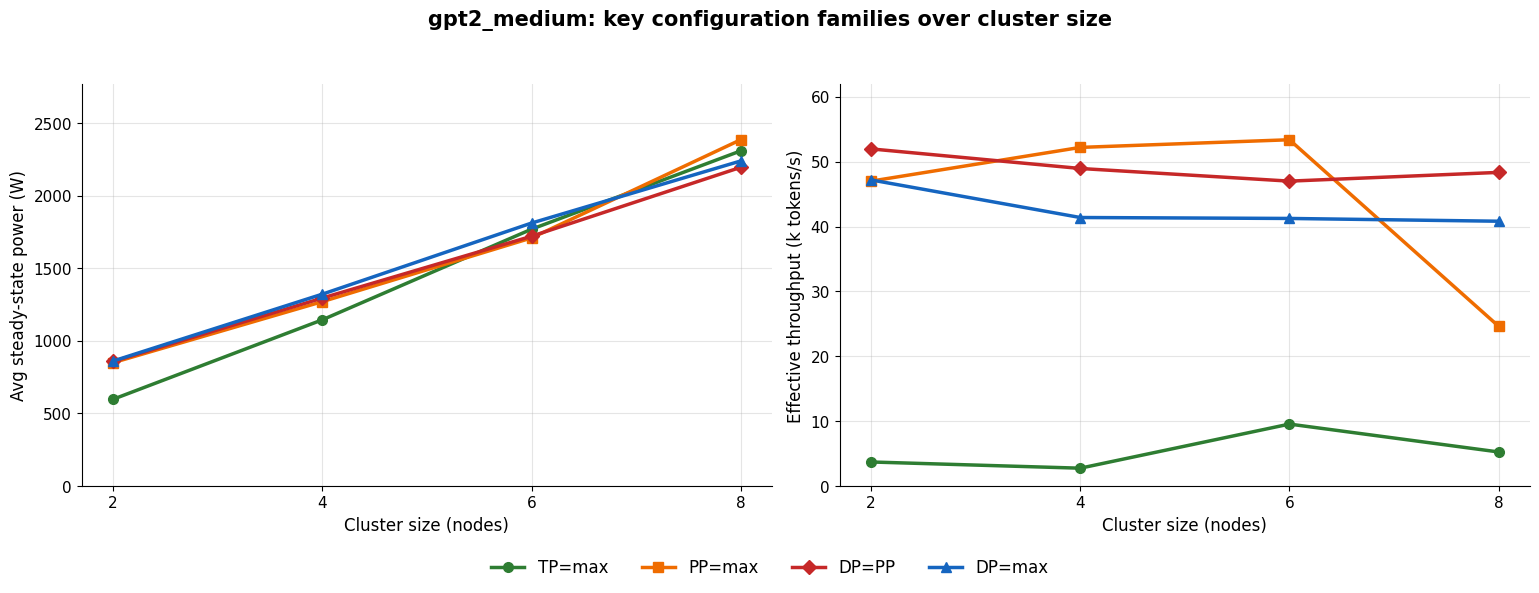

Saved: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/gpt2_medium_sweep_20260512_114447/key_config_power_throughput_cluster_scaling_lines.png
Saved: /u/data3/wat29/scheduling-carbon-aware-3d-parallelism/figures/experiment_plots/gpt2_medium_sweep_20260512_114447/key_config_cluster_scaling_lines.csv


In [49]:
# =====================================================================
# Replacement final plots: fixed-origin lines over cluster size
# =====================================================================
# The previous two panel figures compare separate cluster sizes in separate
# axes. These line plots put cluster size on the x-axis and force the y-axis
# to start at zero, making the cluster-size effect visible.

from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def _find_multinode_base_for_lines(start=None):
    path = Path(start or os.getcwd()).resolve()
    for candidate in (path, *path.parents):
        if (candidate / "power_logs").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    if "MULTINODE_BASE" in globals():
        return Path(MULTINODE_BASE).resolve()
    raise RuntimeError(f"Could not find repo root from {path}")


if "MULTINODE_BASE" in globals():
    MULTINODE_BASE = Path(MULTINODE_BASE).resolve()
else:
    MULTINODE_BASE = _find_multinode_base_for_lines()
MULTINODE_MODEL = globals().get("MULTINODE_MODEL", "gpt2_medium")
MULTINODE_SWEEP_ID = globals().get("MULTINODE_SWEEP_ID", "20260512_114447")
MULTINODE_NODE_COUNTS = globals().get("MULTINODE_NODE_COUNTS", [2, 4, 6, 8])
MULTINODE_GPUS_PER_NODE = globals().get("MULTINODE_GPUS_PER_NODE", 4)
MULTINODE_KEY_ORDER = globals().get("MULTINODE_KEY_ORDER", ["TP=max", "PP=max", "DP=PP", "DP=max"])
MULTINODE_KEY_COLORS = globals().get(
    "MULTINODE_KEY_COLORS",
    {
        "TP=max": "#2E7D32",
        "PP=max": "#EF6C00",
        "DP=PP": "#C62828",
        "DP=max": "#1565C0",
    },
)
MULTINODE_LINE_MARKERS = {
    "TP=max": "o",
    "PP=max": "s",
    "DP=PP": "D",
    "DP=max": "^",
}
ANNOTATE_CONFIG_LABELS = False


def _load_multinode_source_for_lines():
    if "multinode_df" in globals() and not multinode_df.empty:
        return multinode_df.copy()

    out_dir = MULTINODE_BASE / "figures" / "experiment_plots" / f"{MULTINODE_MODEL}_sweep_{MULTINODE_SWEEP_ID}"
    fallback_csv = out_dir / "key_power_throughput_panels.csv"
    if fallback_csv.exists():
        print(f"Using saved key-config summary: {fallback_csv}")
        return pd.read_csv(fallback_csv)

    raise RuntimeError("Run the previous multinode loading cell before this plotting cell.")


def _pick_dp_pp_config(group):
    candidates = group[(group["tp"] == 1) & (group["pp"] > 1) & (group["dp"] > 1)].copy()
    if candidates.empty:
        return None
    candidates["_abs_dp_pp_diff"] = (candidates["pp"] - candidates["dp"]).abs()
    return candidates.sort_values(["_abs_dp_pp_diff", "pp"], ascending=[True, False]).iloc[0]["config"]


def _append_family_pick(rows, group, family, candidates, sort_cols, ascending):
    if candidates.empty:
        print(f"[warn] no {family} representative for n={int(group['n_nodes'].iloc[0])}")
        return

    pick = candidates.sort_values(sort_cols, ascending=ascending).iloc[0].copy()
    pick["model_version"] = family
    rows.append(pick)


def _select_cluster_scaling_representatives(df_source):
    rows = []

    for n_nodes in MULTINODE_NODE_COUNTS:
        group = df_source[df_source["n_nodes"] == n_nodes].copy()
        if group.empty:
            continue

        if "world_size" not in group.columns:
            group["world_size"] = group["n_nodes"] * MULTINODE_GPUS_PER_NODE

        dp_pp_config = _pick_dp_pp_config(group)
        dp_pp = group[group["config"] == dp_pp_config] if dp_pp_config is not None else group.iloc[0:0]
        _append_family_pick(rows, group, "DP=PP", dp_pp, ["pp", "dp"], [False, False])

        max_tp = group["tp"].max()
        tp_max = group[(group["tp"] == max_tp) & (group["config"] != dp_pp_config)].copy()
        _append_family_pick(
            rows,
            group,
            "TP=max",
            tp_max,
            ["pp", "dp", "steady_avg_power_w"],
            [True, False, True],
        )

        max_pp = group["pp"].max()
        pp_max = group[(group["pp"] == max_pp) & (group["config"] != dp_pp_config)].copy()
        _append_family_pick(
            rows,
            group,
            "PP=max",
            pp_max,
            ["tp", "dp", "steady_avg_power_w"],
            [True, False, True],
        )

        world_size = int(group["world_size"].iloc[0])
        dp_max = group[group["dp"] == world_size].copy()
        _append_family_pick(rows, group, "DP=max", dp_max, ["tp", "pp"], [True, True])

    plot_df = pd.DataFrame(rows)
    plot_df["model_version"] = pd.Categorical(plot_df["model_version"], MULTINODE_KEY_ORDER, ordered=True)
    return plot_df.sort_values(["model_version", "n_nodes"]).reset_index(drop=True)


def _tp_pp_dp_label(row):
    return f"T{int(row.tp)}P{int(row.pp)}D{int(row.dp)}"


def _plot_cluster_line_metric(ax, plot_df, metric_col, ylabel, scale=1.0):
    y_all = plot_df[metric_col].to_numpy(dtype=float) / scale
    y_top = max(float(np.nanmax(y_all)) * 1.16, 1.0)

    for family in MULTINODE_KEY_ORDER:
        sub = plot_df[plot_df["model_version"] == family].sort_values("n_nodes")
        if sub.empty:
            continue

        color = MULTINODE_KEY_COLORS[family]
        y = sub[metric_col].to_numpy(dtype=float) / scale
        ax.plot(
            sub["n_nodes"],
            y,
            color=color,
            marker=MULTINODE_LINE_MARKERS[family],
            linewidth=2.5,
            markersize=7,
            label=family,
        )

        if ANNOTATE_CONFIG_LABELS:
            for row, y_value in zip(sub.itertuples(index=False), y):
                ax.annotate(
                    _tp_pp_dp_label(row),
                    xy=(row.n_nodes, y_value),
                    xytext=(0, 8),
                    textcoords="offset points",
                    ha="center",
                    fontsize=8.5,
                    color=color,
                )

    ax.set_xticks(MULTINODE_NODE_COUNTS)
    ax.set_xlabel("Cluster size (nodes)", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_ylim(0, y_top)
    ax.grid(True, alpha=0.32)
    ax.tick_params(labelsize=11)


multinode_source_df = _load_multinode_source_for_lines()
multinode_cluster_line_df = _select_cluster_scaling_representatives(multinode_source_df)

print("Representative configs used for cluster-size line plots:")
print(
    multinode_cluster_line_df[[
        "model_version", "n_nodes", "world_size", "config",
        "steady_avg_power_w", "throughput_tok_s", "duration_s",
    ]].to_string(index=False)
)

out_dir = MULTINODE_BASE / "figures" / "experiment_plots" / f"{MULTINODE_MODEL}_sweep_{MULTINODE_SWEEP_ID}"
out_dir.mkdir(parents=True, exist_ok=True)
line_summary_path = out_dir / "key_config_cluster_scaling_lines.csv"
multinode_cluster_line_df.assign(
    model_version=multinode_cluster_line_df["model_version"].astype(str),
    throughput_k_tok_s=multinode_cluster_line_df["throughput_tok_s"] / 1000,
).to_csv(line_summary_path, index=False)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.0), sharex=True)
_plot_cluster_line_metric(
    axes[0],
    multinode_cluster_line_df,
    metric_col="steady_avg_power_w",
    ylabel="Avg steady-state power (W)",
)
_plot_cluster_line_metric(
    axes[1],
    multinode_cluster_line_df,
    metric_col="throughput_tok_s",
    ylabel="Effective throughput (k tokens/s)",
    scale=1000,
)

handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(f"{MULTINODE_MODEL}: key configuration families over cluster size", fontsize=15, fontweight="bold", y=0.98)
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=len(labels),
    frameon=False,
    fontsize=12,
)
plt.tight_layout(rect=[0, 0.08, 1, 0.94])

line_plot_path = out_dir / "key_config_power_throughput_cluster_scaling_lines.png"
plt.savefig(line_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {line_plot_path}")
print(f"Saved: {line_summary_path}")